# Loan Approval & Risk Analysis Using EDA

### Problem Statement
Financial institutions must evaluate loan applications to minimize default risk while maximizing approvals. This notebook performs exploratory data analysis on applicant data to identify which factors are *statistically* associated with loan approval, not just visually associated.

### Objective
- Clean and preprocess applicant data
- Test (not just eyeball) which variables are associated with `Loan_Status`, using chi-square tests for categorical variables and point-biserial correlation for numeric variables
- Quantify approval-rate differences across segments
- Flag data quality issues (missingness patterns, outliers, class imbalance) that affect how the findings should be read

### Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, pointbiserialr
import warnings
warnings.filterwarnings("ignore")

### Loading the Dataset

In [2]:
df = pd.read_csv("../data/train.csv")
raw_df = df.copy()  # untouched snapshot, used later to build a leakage-free modeling pipeline
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [3]:
df.shape

(614, 13)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


### Missing Values

In [5]:
missing_pct = (df.isnull().sum() / len(df) * 100).round(2)
missing_pct[missing_pct > 0].sort_values(ascending=False)

Credit_History      8.14
Self_Employed       5.21
LoanAmount          3.58
Dependents          2.44
Loan_Amount_Term    2.28
Gender              2.12
Married             0.49
dtype: float64

### Target Class Balance

Checking this *before* drawing conclusions from approval-rate comparisons — with a 69/31 split, a model that just predicted "approve everyone" would already be right ~69% of the time. Any accuracy claims later need to beat that baseline, and approval-rate gaps need to be read against this base rate, not against 50%.

In [6]:
class_balance = df['Loan_Status'].value_counts(normalize=True) * 100
class_balance.round(2)

Loan_Status
Y    68.73
N    31.27
Name: proportion, dtype: float64

### Does Missing `Credit_History` Carry Signal?

Before imputing the 8.14% missing `Credit_History` values with the mode, checking whether "missing" behaves like a distinct group. If it does, mode-imputation would be quietly destroying information rather than filling in noise.

In [7]:
df['CH_missing'] = df['Credit_History'].isnull()
ch_missing_approval = df.groupby('CH_missing')['Loan_Status'].apply(lambda x: (x == 'Y').mean() * 100).round(2)
ch_missing_approval

CH_missing
False    68.26
True     74.00
Name: Loan_Status, dtype: float64

**Finding:** applicants with missing `Credit_History` are approved at 74.0% vs 68.3% for those with a recorded value (n=50 missing, small sample — treat as a flag, not a strong claim). It is *not* the "automatic reject" pattern one might assume, so mode-imputing this column is a reasonable simplification here, not an obviously harmful one. Noting this rather than silently imputing is the point.

### Data Cleaning

**Note on scope:** the imputation below uses statistics computed on the full 614-row dataset, which is standard practice for descriptive EDA (there's no train/test split at this stage — we're describing the sample we have, not evaluating a model's ability to generalize). The modeling section further down does **not** reuse this cleaned `df` — it rebuilds cleaning from `raw_df` with the train/test split happening *first*, so imputation statistics (mode/median) are computed on training data only. Using this EDA-level `df` to fit or evaluate a model would leak test-set information into the imputed values; that distinction is why two separate cleaning passes exist.

In [8]:
df.drop(columns=['CH_missing'], inplace=True)  # was only for the check above

# Categorical: impute with mode
cat_cols = ['Gender', 'Married', 'Dependents', 'Self_Employed']
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# Numeric: impute with median
num_cols = ['LoanAmount', 'Loan_Amount_Term']
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# Credit_History: impute with mode (justified by the check above)
df['Credit_History'] = df['Credit_History'].fillna(df['Credit_History'].mode()[0])

# Dependents: "3+" -> 3, cast to int
df['Dependents'] = df['Dependents'].replace('3+', '3').astype(int)

# Drop identifier column - not predictive
df.drop(columns=['Loan_ID'], inplace=True)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Gender             614 non-null    object 
 1   Married            614 non-null    object 
 2   Dependents         614 non-null    int64  
 3   Education          614 non-null    object 
 4   Self_Employed      614 non-null    object 
 5   ApplicantIncome    614 non-null    int64  
 6   CoapplicantIncome  614 non-null    float64
 7   LoanAmount         614 non-null    float64
 8   Loan_Amount_Term   614 non-null    float64
 9   Credit_History     614 non-null    float64
 10  Property_Area      614 non-null    object 
 11  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(2), object(6)
memory usage: 57.7+ KB


In [9]:
df.describe()

,Dependents,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,614.000000,614.000000,614.000000,614.000000
mean,0.744300,5403.459283,1621.245798,145.752443,342.410423,0.855049
std,1.009623,6109.041673,2926.248369,84.107233,64.428629,0.352339
min,0.000000,150.000000,0.000000,9.000000,12.000000,0.000000
25%,0.000000,2877.500000,0.000000,100.250000,360.000000,1.000000
50%,0.000000,3812.500000,1188.500000,128.000000,360.000000,1.000000
75%,1.000000,5795.000000,2297.250000,164.750000,360.000000,1.000000
max,3.000000,81000.000000,41667.000000,700.000000,480.000000,1.000000


### Feature Engineering

`ApplicantIncome` alone is an incomplete picture of household finances — many applicants have a co-applicant (often a spouse) contributing income. Adding two engineered features before analysis:
- `Total_Income` = ApplicantIncome + CoapplicantIncome
- `Loan_to_Income` = LoanAmount / Total_Income (a rough affordability ratio)

In [10]:
df['Total_Income'] = df['ApplicantIncome'] + df['CoapplicantIncome']
df['Loan_to_Income'] = df['LoanAmount'] / df['Total_Income']
df[['ApplicantIncome', 'CoapplicantIncome', 'Total_Income', 'LoanAmount', 'Loan_to_Income']].head()

,ApplicantIncome,CoapplicantIncome,Total_Income,LoanAmount,Loan_to_Income
0,5849,0.0,5849.0,128.0,0.021884
1,4583,1508.0,6091.0,128.0,0.021015
2,3000,0.0,3000.0,66.0,0.022000
3,2583,2358.0,4941.0,120.0,0.024287
4,6000,0.0,6000.0,141.0,0.023500


---
## Exploratory Data Analysis

## Univariate Analysis

**Loan Status Distribution**

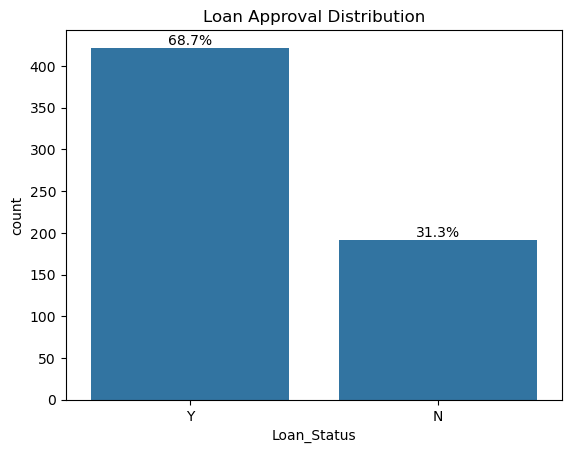

In [11]:
ax = sns.countplot(x='Loan_Status', data=df)
plt.title("Loan Approval Distribution")
for p in ax.patches:
    pct = p.get_height() / len(df) * 100
    ax.annotate(f'{pct:.1f}%', (p.get_x() + p.get_width()/2, p.get_height()), ha='center', va='bottom')
plt.savefig('../images/loan_app_dist.png', dpi=120, bbox_inches='tight')
plt.show()

**Credit History Distribution**

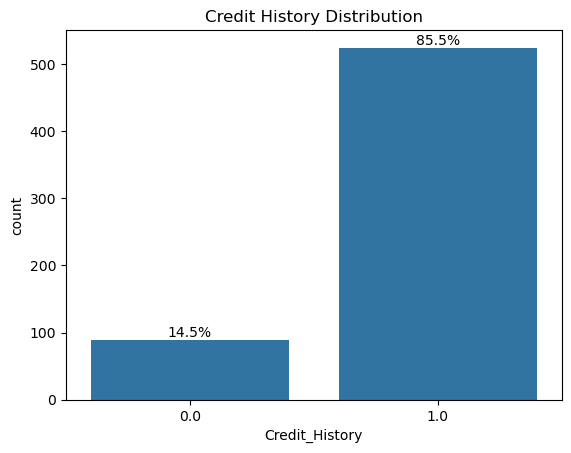

In [12]:
ax = sns.countplot(x='Credit_History', data=df)
plt.title("Credit History Distribution")
for p in ax.patches:
    pct = p.get_height() / len(df) * 100
    ax.annotate(f'{pct:.1f}%', (p.get_x() + p.get_width()/2, p.get_height()), ha='center', va='bottom')
plt.savefig('../images/credit_hist.png', dpi=120, bbox_inches='tight')
plt.show()

**Applicant Income Distribution & Outliers**

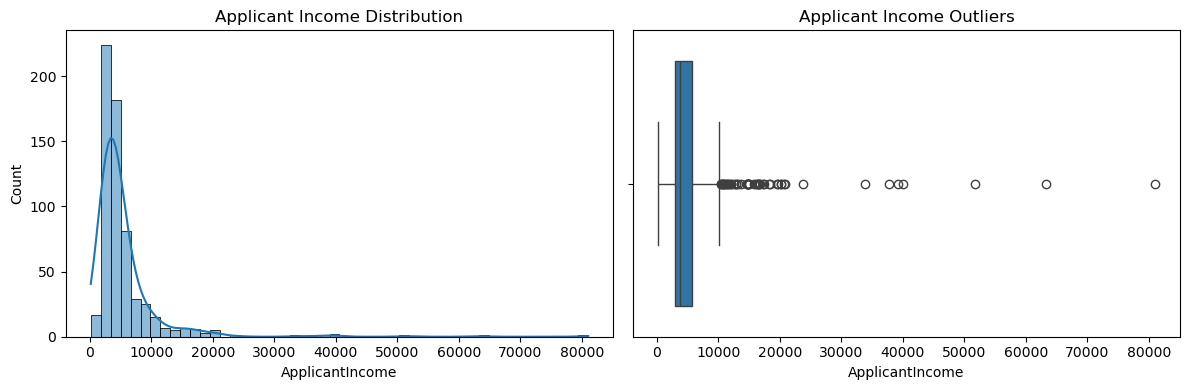

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['ApplicantIncome'], kde=True, ax=axes[0])
axes[0].set_title("Applicant Income Distribution")
sns.boxplot(x=df['ApplicantIncome'], ax=axes[1])
axes[1].set_title("Applicant Income Outliers")
plt.tight_layout()
plt.savefig('../images/income_dist.png', dpi=120, bbox_inches='tight')
plt.show()

**Loan Amount Distribution & Outliers**

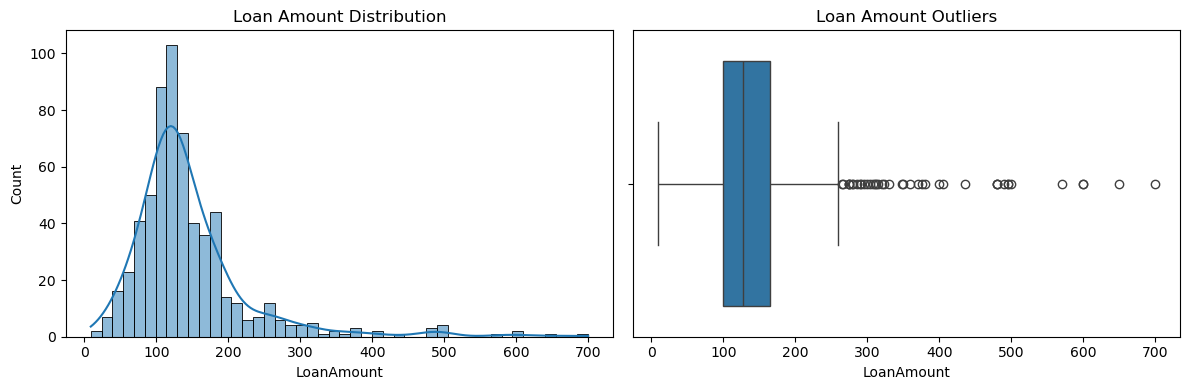

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['LoanAmount'], kde=True, ax=axes[0])
axes[0].set_title("Loan Amount Distribution")
sns.boxplot(x=df['LoanAmount'], ax=axes[1])
axes[1].set_title("Loan Amount Outliers")
plt.tight_layout()
plt.savefig('../images/loanamount_dist.png', dpi=120, bbox_inches='tight')
plt.show()

**Quantifying outliers (IQR method)**

In [15]:
def iqr_outliers(series):
    Q1, Q3 = series.quantile([0.25, 0.75])
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    n_out = ((series < lower) | (series > upper)).sum()
    return n_out, n_out/len(series)*100, (lower, upper)

for col in ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount']:
    n, pct, bounds = iqr_outliers(df[col])
    print(f"{col:20s} outliers={n:4d} ({pct:.1f}%)  IQR bounds=({bounds[0]:.0f}, {bounds[1]:.0f})  max={df[col].max():.0f}")

ApplicantIncome      outliers=  50 (8.1%)  IQR bounds=(-1499, 10171)  max=81000
CoapplicantIncome    outliers=  18 (2.9%)  IQR bounds=(-3446, 5743)  max=41667
LoanAmount           outliers=  41 (6.7%)  IQR bounds=(4, 262)  max=700


**Finding:** `ApplicantIncome` has 50 outliers (8.1% of rows) by the IQR rule, with a max of 81,000 against an IQR upper bound of ~10,171 — heavily right-skewed. `LoanAmount` has 41 outliers (6.7%). These aren't removed here (EDA should show the data as it is), but any downstream model would need to log-transform or cap these before fitting — raw linear models would let a handful of extreme rows dominate.

## Bivariate Analysis — Categorical Variables vs Loan Status

For each categorical variable: approval rate by group, and a chi-square test of independence against `Loan_Status` (H0: the variable and approval are independent; p < 0.05 = statistically significant association at 95% confidence).

In [16]:
def chi_square_test(df, col, target='Loan_Status'):
    ct = pd.crosstab(df[col], df[target])
    chi2, p, dof, expected = chi2_contingency(ct)
    return chi2, p

cat_vars = ['Credit_History', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']
chi_results = []
for col in cat_vars:
    chi2, p = chi_square_test(df, col)
    chi_results.append({'Variable': col, 'Chi2': round(chi2, 2), 'p_value': round(p, 5), 'Significant (p<0.05)': p < 0.05})

chi_results_df = pd.DataFrame(chi_results).sort_values('Chi2', ascending=False).reset_index(drop=True)
chi_results_df

,Variable,Chi2,p_value,Significant (p<0.05)
0,Credit_History,176.11,0.00000,True
1,Property_Area,12.30,0.00214,True
2,Married,4.73,0.02961,True
3,Education,4.09,0.04310,True
4,Dependents,3.15,0.36887,False
5,Gender,0.11,0.73915,False
6,Self_Employed,0.00,1.00000,False


**Credit History vs Loan Status**

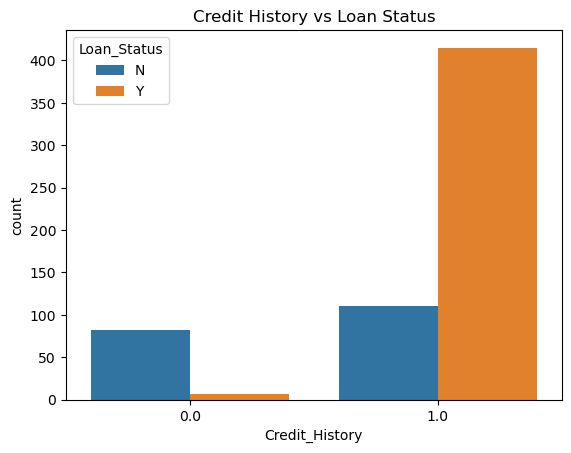

Approval rate by Credit_History (%):
Loan_Status         N      Y
Credit_History              
0.0             92.13   7.87
1.0             20.95  79.05


In [17]:
ax = sns.countplot(x='Credit_History', hue='Loan_Status', data=df)
plt.title("Credit History vs Loan Status")
plt.show()

print("Approval rate by Credit_History (%):")
print((pd.crosstab(df['Credit_History'], df['Loan_Status'], normalize='index') * 100).round(2))

**Finding:** this is the strongest relationship in the dataset by a wide margin — chi2 = 176.1, p < 0.0001. Applicants with `Credit_History = 1` are approved 79.1% of the time vs just 7.9% for `Credit_History = 0`. That's a ~71 percentage-point gap, which is what actually supports the "credit history is the dominant factor" claim — not just the visual gap in the countplot.

**Dependents vs Loan Status**

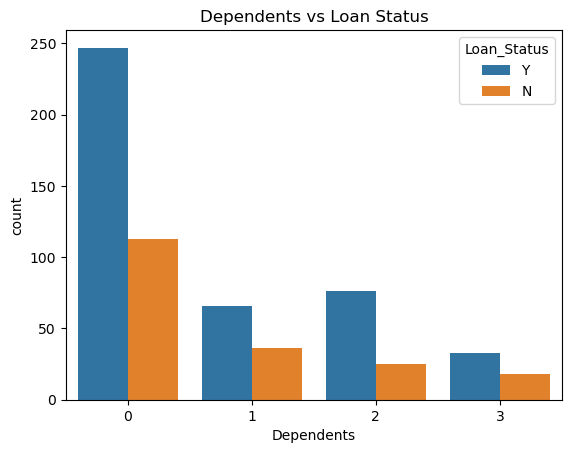

Approval rate by Dependents (%):
Loan_Status      N      Y
Dependents               
0            31.39  68.61
1            35.29  64.71
2            24.75  75.25
3            35.29  64.71


In [18]:
ax = sns.countplot(x='Dependents', hue='Loan_Status', data=df)
plt.title("Dependents vs Loan Status")
plt.show()

print("Approval rate by Dependents (%):")
print((pd.crosstab(df['Dependents'], df['Loan_Status'], normalize='index') * 100).round(2))

**Finding — this corrects a claim from the earlier version of this project.** The chi-square test for `Dependents` gives p = 0.369 — **not statistically significant.** Approval rates by dependent count (68.6%, 64.7%, 75.3%, 64.7% for 0/1/2/3) don't show a clean "fewer dependents = higher approval" pattern; 2 dependents actually has the *highest* approval rate. The earlier claim that "applicants with no dependents have higher approval rates" was an overread of a countplot and isn't supported once tested. Dependents is not a meaningful driver of approval in this data.

**Property Area vs Loan Status**

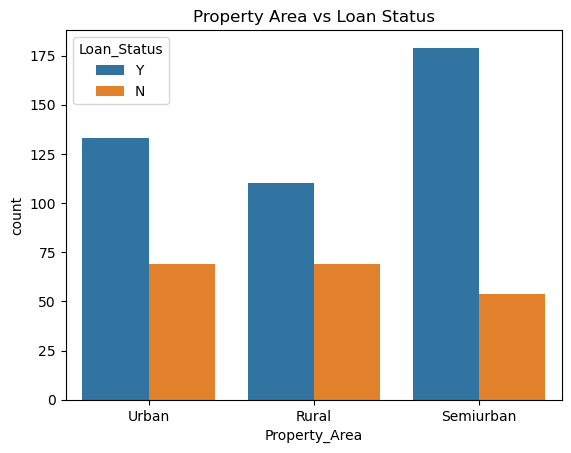

Approval rate by Property_Area (%):
Loan_Status        N      Y
Property_Area              
Rural          38.55  61.45
Semiurban      23.18  76.82
Urban          34.16  65.84


In [19]:
ax = sns.countplot(x='Property_Area', hue='Loan_Status', data=df)
plt.title("Property Area vs Loan Status")
plt.show()

print("Approval rate by Property_Area (%):")
print((pd.crosstab(df['Property_Area'], df['Loan_Status'], normalize='index') * 100).round(2))

**Finding:** significant (chi2 = 12.3, p = 0.0021). Semiurban applicants are approved 76.8% of the time vs 65.8% (Urban) and 61.5% (Rural) — this claim holds up under testing.

**Education vs Loan Status**

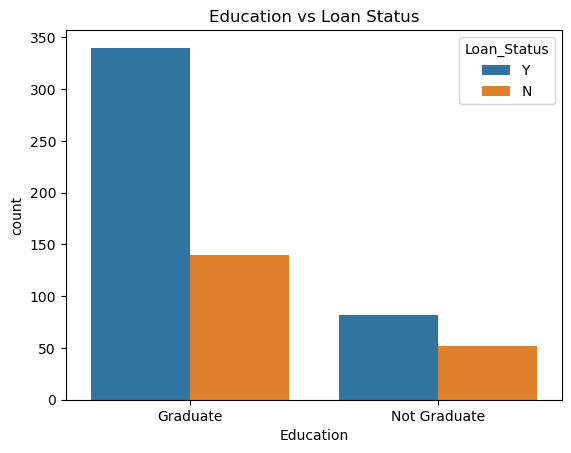

Approval rate by Education (%):
Loan_Status       N      Y
Education                 
Graduate      29.17  70.83
Not Graduate  38.81  61.19


In [20]:
ax = sns.countplot(x='Education', hue='Loan_Status', data=df)
plt.title("Education vs Loan Status")
plt.show()

print("Approval rate by Education (%):")
print((pd.crosstab(df['Education'], df['Loan_Status'], normalize='index') * 100).round(2))

**Finding:** significant at the uncorrected α=0.05 level (chi2 = 4.09, p = 0.043 — just under the threshold), with Graduates approved 70.8% vs 61.2% for non-graduates. `Gender` (p=0.74) and `Self_Employed` (p=1.00) show no relationship at all, and `Married` is similarly borderline (p=0.030). **Whether Education and Married survive correction for running 13 tests is checked explicitly below** — flagging that now rather than calling this a confirmed "secondary driver" prematurely.

## Multivariate Analysis

**Correlation Matrix (numeric features, including engineered ones)**

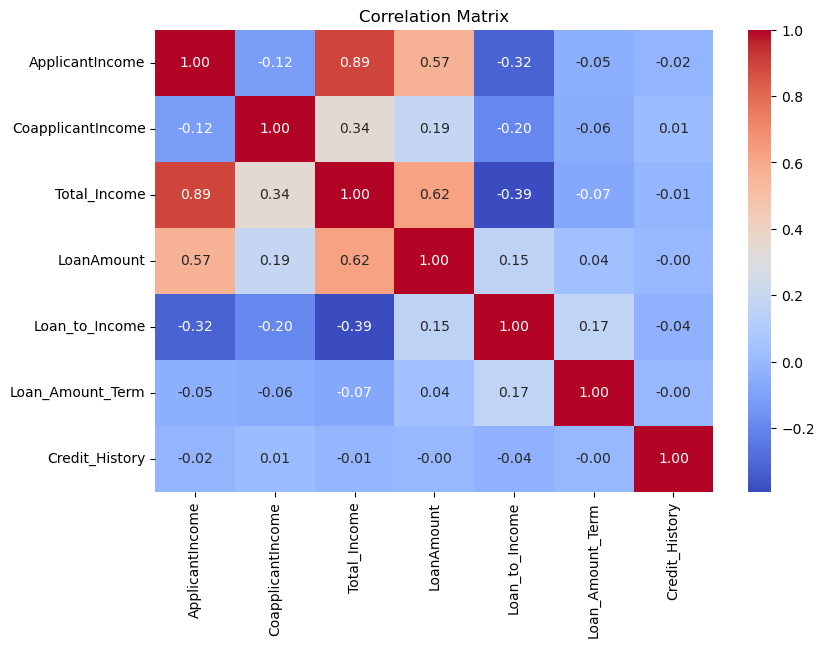

In [21]:
corr_cols = ['ApplicantIncome', 'CoapplicantIncome', 'Total_Income', 'LoanAmount', 'Loan_to_Income', 'Loan_Amount_Term', 'Credit_History']
corr = df[corr_cols].corr()
plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Matrix")
plt.savefig('../images/corr_matrix.png', dpi=120, bbox_inches='tight')
plt.show()

**Point-biserial correlation of numeric variables with `Loan_Status`**

Chi-square doesn't apply to continuous variables — using point-biserial correlation instead (equivalent to Pearson correlation between a continuous variable and a binary target).

In [22]:
df['Loan_Status_bin'] = (df['Loan_Status'] == 'Y').astype(int)

pb_results = []
for col in ['ApplicantIncome', 'CoapplicantIncome', 'Total_Income', 'LoanAmount', 'Loan_to_Income', 'Loan_Amount_Term']:
    r, p = pointbiserialr(df['Loan_Status_bin'], df[col])
    pb_results.append({'Variable': col, 'r': round(r, 4), 'p_value': round(p, 4), 'Significant (p<0.05)': p < 0.05})

pb_df = pd.DataFrame(pb_results).sort_values('r', key=abs, ascending=False).reset_index(drop=True)
pb_df

,Variable,r,p_value,Significant (p<0.05)
0,Loan_to_Income,-0.0861,0.0328,True
1,CoapplicantIncome,-0.0592,0.1429,False
2,LoanAmount,-0.0332,0.4113,False
3,Total_Income,-0.0313,0.4392,False
4,Loan_Amount_Term,-0.0225,0.5771,False
5,ApplicantIncome,-0.0047,0.9073,False


**Finding — this is the most important correction to the original narrative.** None of the raw income or loan-amount variables are meaningfully correlated with approval: `ApplicantIncome` (r = -0.005, p = 0.91), `Total_Income` (r = -0.031, p = 0.44), `LoanAmount` (r = -0.033, p = 0.41) are all statistically indistinguishable from zero. Only the engineered `Loan_to_Income` ratio reaches significance, and even then it's weak (r = -0.086, p = 0.033).

In other words: **how much someone earns or borrows has essentially no relationship with whether they get approved in this dataset — only whether they have a track record of repaying (Credit_History) does, along with weaker effects from property area and education.** This is a stronger, more specific version of the "credit history dominates" claim than the original README made — it's not just that credit history matters more than income, it's that income barely matters at all.

---
## Summary of Statistical Findings

In [23]:
summary = pd.concat([
    chi_results_df.assign(Test='Chi-square', r_or_chi2=chi_results_df['Chi2']),
    pb_df.assign(Test='Point-biserial r', r_or_chi2=pb_df['r'])
], ignore_index=True)[['Variable', 'Test', 'r_or_chi2', 'p_value', 'Significant (p<0.05)']]
summary.sort_values('Significant (p<0.05)', ascending=False)

,Variable,Test,r_or_chi2,p_value,Significant (p<0.05)
0,Credit_History,Chi-square,176.1100,0.00000,True
1,Property_Area,Chi-square,12.3000,0.00214,True
2,Married,Chi-square,4.7300,0.02961,True
3,Education,Chi-square,4.0900,0.04310,True
7,Loan_to_Income,Point-biserial r,-0.0861,0.03280,True
4,Dependents,Chi-square,3.1500,0.36887,False
5,Gender,Chi-square,0.1100,0.73915,False
6,Self_Employed,Chi-square,0.0000,1.00000,False
8,CoapplicantIncome,Point-biserial r,-0.0592,0.14290,False
9,LoanAmount,Point-biserial r,-0.0332,0.41130,False


### Correcting for Multiple Comparisons

13 hypothesis tests were run above (7 chi-square + 6 point-biserial), each at an uncorrected α = 0.05. That means roughly 13 × 0.05 ≈ 0.65 false positives are expected from chance alone, even if none of these variables actually mattered. `Married` (p=0.030) and `Education` (p=0.043) — the two "borderline" findings — sit exactly in the range this predicts. Applying a Bonferroni correction (α = 0.05 / 13 ≈ 0.0038) to see which findings actually survive:

In [24]:
ALPHA = 0.05
N_TESTS = 13
BONFERRONI_ALPHA = ALPHA / N_TESTS

summary['Significant (Bonferroni)'] = summary['p_value'] < BONFERRONI_ALPHA
print(f"Bonferroni-corrected alpha: {BONFERRONI_ALPHA:.5f}")
summary[['Variable', 'Test', 'p_value', 'Significant (p<0.05)', 'Significant (Bonferroni)']].sort_values('p_value')

Bonferroni-corrected alpha: 0.00385


,Variable,Test,p_value,Significant (p<0.05),Significant (Bonferroni)
0,Credit_History,Chi-square,0.00000,True,True
1,Property_Area,Chi-square,0.00214,True,True
2,Married,Chi-square,0.02961,True,False
7,Loan_to_Income,Point-biserial r,0.03280,True,False
3,Education,Chi-square,0.04310,True,False
8,CoapplicantIncome,Point-biserial r,0.14290,False,False
4,Dependents,Chi-square,0.36887,False,False
9,LoanAmount,Point-biserial r,0.41130,False,False
10,Total_Income,Point-biserial r,0.43920,False,False
11,Loan_Amount_Term,Point-biserial r,0.57710,False,False


**Finding:** only `Credit_History` and `Property_Area` survive Bonferroni correction. `Married` and `Education` do not — at this sample size and this many tests, they're statistically indistinguishable from noise. The honest framing for these two is not "borderline significant, secondary signal" (which implies a real but weak effect) — it's "cannot be distinguished from a false positive given how many tests were run." They're kept in the writeup as things worth re-testing on a larger or independent dataset, not as findings this project has established.

## Key Insights (Quantified)

- **Class balance:** 68.7% approved / 31.3% rejected — any future model needs to beat a 68.7% "approve everyone" baseline to add value
- **Credit History is the dominant factor** (chi2 = 176.1, p < 0.0001): 79.1% approval with good credit history vs 7.9% without — a 71-point gap
- **Income variables (Applicant, Coapplicant, Total) have no significant relationship with approval** (all p > 0.4) — this is the most counterintuitive and important finding, and directly contradicts the assumption that income drives approval
- **Property Area matters** (chi2 = 12.3, p = 0.002): Semiurban applicants approved at 76.8% vs 61.5–65.8% elsewhere
- **Education and Married are significant only at the uncorrected level** (p = 0.043, p = 0.030) — flagged for the Bonferroni check below rather than treated as confirmed
- **Dependents, Gender, and Self-Employment show no significant relationship with approval** (p = 0.37, 0.74, 1.00) — the original assumption that "fewer dependents = higher approval" does not hold up under testing
- **Missing Credit_History (8.1% of rows) is not an automatic-reject signal** — that group was actually approved slightly more often (74.0% vs 68.3%), though on a small sample (n=50)
- **ApplicantIncome and LoanAmount are right-skewed with real outliers** (8.1% and 6.7% of rows by IQR rule) — any model built on this data needs a log transform or capping before fitting

---
# Baseline Model: Does It Hold Up When Controlled Jointly?

The EDA above tests each variable **in isolation**. That leaves an open question: does `Credit_History` still dominate once every other variable is accounted for at the same time — or is some of its apparent effect actually leaking through a correlated variable? A baseline logistic regression answers this, and gives an actual, honest performance number instead of a plausible-sounding narrative.

**Why logistic regression, and not a tree/ensemble model first:** the goal here is to validate the EDA, not to chase accuracy. Logistic regression coefficients map directly onto "does this variable matter, controlling for the others" — the same question the chi-square tests asked, just jointly instead of one at a time. A more complex model would answer a different question (best achievable accuracy) and obscure the comparison to the EDA. That's future scope, not this step.

### Prepare Modeling Data — Leakage-Free

Building this from `raw_df`, not the EDA `df` above. Encoding categorical labels to numeric (a deterministic recoding, not a statistical fit — safe to do before splitting) but **not imputing yet** — imputation values need to come from the training set only.

In [25]:
from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                              roc_curve, ConfusionMatrixDisplay)

model_raw = raw_df.drop(columns=['Loan_ID']).copy()
model_raw['Dependents'] = model_raw['Dependents'].replace('3+', '3')  # still has NaNs; cast to int after imputing

binary_map = {'Male': 1, 'Female': 0, 'Yes': 1, 'No': 0, 'Graduate': 1, 'Not Graduate': 0}
model_raw['Gender'] = model_raw['Gender'].map(binary_map)
model_raw['Married'] = model_raw['Married'].map(binary_map)
model_raw['Education'] = model_raw['Education'].map(binary_map)
model_raw['Self_Employed'] = model_raw['Self_Employed'].map(binary_map)
model_raw = pd.get_dummies(model_raw, columns=['Property_Area'], drop_first=True)
model_raw['Loan_Status_bin'] = (model_raw['Loan_Status'] == 'Y').astype(int)

X = model_raw.drop(columns=['Loan_Status', 'Loan_Status_bin'])
y = model_raw['Loan_Status_bin']
X.isnull().sum()[X.isnull().sum() > 0]

Gender              13
Married              3
Dependents          15
Self_Employed       32
LoanAmount          22
Loan_Amount_Term    14
Credit_History      50
dtype: int64

### Train/Test Split — Before Any Imputation

Splitting first, on the still-missing data. Imputation values (mode/median) get fit on `X_train` only and applied to both sets — the test set never influences what gets filled into training rows, or vice versa.

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train: {X_train.shape[0]} rows ({y_train.mean()*100:.1f}% approved)")
print(f"Test:  {X_test.shape[0]} rows ({y_test.mean()*100:.1f}% approved)")

# Impute using TRAIN statistics only
mode_cols = ['Gender', 'Married', 'Dependents', 'Self_Employed', 'Credit_History']
median_cols = ['LoanAmount', 'Loan_Amount_Term']

for col in mode_cols:
    fill_val = X_train[col].mode()[0]
    X_train[col] = X_train[col].fillna(fill_val)
    X_test[col] = X_test[col].fillna(fill_val)

for col in median_cols:
    fill_val = X_train[col].median()
    X_train[col] = X_train[col].fillna(fill_val)
    X_test[col] = X_test[col].fillna(fill_val)

X_train['Dependents'] = X_train['Dependents'].astype(int)
X_test['Dependents'] = X_test['Dependents'].astype(int)

# Feature engineering happens after imputation, per-row arithmetic - no leakage risk here
for d in (X_train, X_test):
    d['Total_Income'] = d['ApplicantIncome'] + d['CoapplicantIncome']
    d['Loan_to_Income'] = d['LoanAmount'] / d['Total_Income']

# Log-transform the right-skewed variables identified earlier
for col in ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Total_Income']:
    X_train[col] = np.log1p(X_train[col])
    X_test[col] = np.log1p(X_test[col])

# Total_Income dropped: perfectly collinear with ApplicantIncome + CoapplicantIncome (see multicollinearity note)
X_train = X_train.drop(columns=['Total_Income'])
X_test = X_test.drop(columns=['Total_Income'])

X_train.isnull().sum().sum(), X_test.isnull().sum().sum()  # confirm no missing values remain

Train: 491 rows (68.6% approved)
Test:  123 rows (69.1% approved)


(np.int64(0), np.int64(0))

### Scale Only the Continuous Features

`StandardScaler` should not touch binary (0/1) or one-hot columns. Scaling a binary variable changes its coefficient's unit from "0 vs 1" to "1 standard deviation" — for `Credit_History`, whose SD is ~0.35 (85.5% of applicants have it), those are very different sizes, and reporting a per-SD odds ratio as if it were the direct 0-vs-1 effect understates it by nearly 10x. Only genuinely continuous features get scaled; `Credit_History`, `Gender`, `Married`, `Education`, `Self_Employed`, `Dependents`, and the `Property_Area` dummies stay on their natural scale, so their coefficients are directly interpretable with no conversion needed.

In [27]:
binary_or_dummy_cols = ['Credit_History', 'Gender', 'Married', 'Education', 'Self_Employed',
                        'Dependents', 'Property_Area_Semiurban', 'Property_Area_Urban']
continuous_cols = [c for c in X_train.columns if c not in binary_or_dummy_cols]
print("Scaling:", continuous_cols)

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[continuous_cols] = scaler.fit_transform(X_train[continuous_cols])
X_test_scaled[continuous_cols] = scaler.transform(X_test[continuous_cols])

Scaling: ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Loan_to_Income']


### Baseline Comparison

Before trusting any model metric, establishing what "doing nothing" scores. A model has to beat this to be worth anything.

In [28]:
majority_baseline = max(y_test.mean(), 1 - y_test.mean())
print(f"Majority-class baseline (always predict 'Approved'): {majority_baseline*100:.1f}% accuracy")

Majority-class baseline (always predict 'Approved'): 69.1% accuracy


### Fit Logistic Regression

Using `class_weight='balanced'` — with a 69/31 split, an unweighted model would happily default toward predicting "approved" for everyone and still look accurate. Balancing forces it to actually learn the minority (rejected) class.

In [29]:
log_reg = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

y_pred = log_reg.predict(X_test_scaled)
y_pred_proba = log_reg.predict_proba(X_test_scaled)[:, 1]

print(classification_report(y_test, y_pred, target_names=['Rejected', 'Approved']))
print(f"ROC-AUC: {roc_auc_score(y_test, y_pred_proba):.3f}")
print(f"Test accuracy: {(y_pred == y_test).mean()*100:.1f}%  (majority baseline: {majority_baseline*100:.1f}%)")

              precision    recall  f1-score   support

    Rejected       0.68      0.66      0.67        38
    Approved       0.85      0.86      0.85        85

    accuracy                           0.80       123
   macro avg       0.76      0.76      0.76       123
weighted avg       0.80      0.80      0.80       123

ROC-AUC: 0.864
Test accuracy: 79.7%  (majority baseline: 69.1%)


**Reading this correctly:** overall accuracy alone is a weak metric here given the imbalance. The metric that matters most for a lender is **recall on the Rejected class** — missing a bad loan (predicting "approve" when the true label is "reject") is the expensive error, not the reverse. Reporting that number specifically, not just headline accuracy, is what separates "I trained a model" from "I understood what the model needs to be good at."   

**Confusion Matrix**

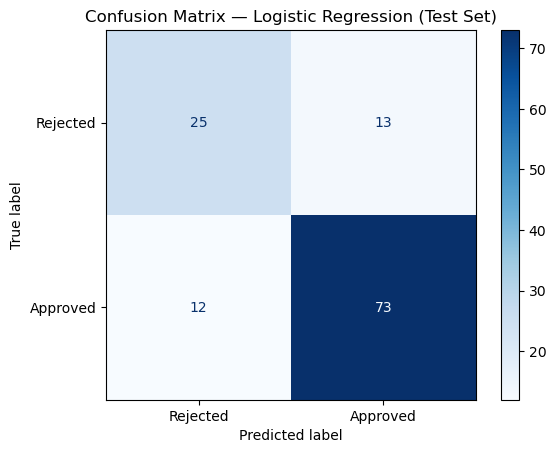

In [30]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Rejected', 'Approved'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix — Logistic Regression (Test Set)")
plt.savefig('../images/confusion_matrix.png', dpi=120, bbox_inches='tight')
plt.show()

**ROC Curve**

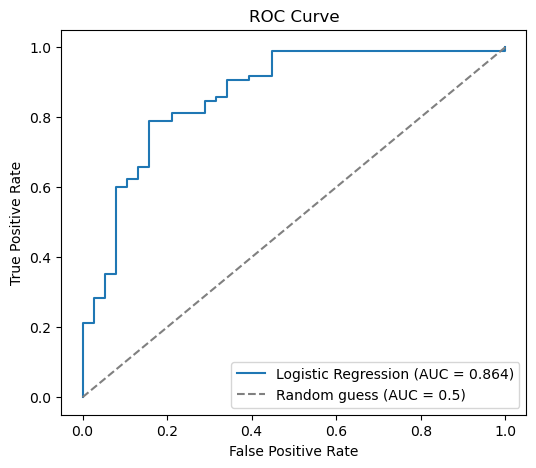

In [31]:
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc_score(y_test, y_pred_proba):.3f})")
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess (AUC = 0.5)')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.savefig('../images/roc_curve.png', dpi=120, bbox_inches='tight')
plt.show()

### Cross-Validation — Repeated, Not Single-Pass

A single 5-fold split gives a wide, noisy interval (5 estimates isn't much to average). Using `RepeatedStratifiedKFold` (5 folds × 10 repeats = 50 estimates) tightens the confidence interval around the mean instead of just reporting one wide-uncertainty run.

In [32]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
cv_auc = cross_val_score(log_reg, X_train_scaled, y_train, cv=cv, scoring='roc_auc')
cv_acc = cross_val_score(log_reg, X_train_scaled, y_train, cv=cv, scoring='accuracy')

auc_se = cv_auc.std() / np.sqrt(len(cv_auc))
acc_se = cv_acc.std() / np.sqrt(len(cv_acc))

print(f"Repeated CV ROC-AUC: {cv_auc.mean():.3f}  (std across {len(cv_auc)} folds: {cv_auc.std():.3f})")
print(f"  95% CI on the mean: [{cv_auc.mean()-1.96*auc_se:.3f}, {cv_auc.mean()+1.96*auc_se:.3f}]")
print(f"Repeated CV Accuracy: {cv_acc.mean()*100:.1f}%  (std across {len(cv_acc)} folds: {cv_acc.std()*100:.1f}%)")
print(f"  95% CI on the mean: [{(cv_acc.mean()-1.96*acc_se)*100:.1f}%, {(cv_acc.mean()+1.96*acc_se)*100:.1f}%]")

Repeated CV ROC-AUC: 0.714  (std across 50 folds: 0.055)
  95% CI on the mean: [0.699, 0.730]
Repeated CV Accuracy: 72.6%  (std across 50 folds: 3.9%)
  95% CI on the mean: [71.5%, 73.7%]


**This is the number to report: ROC-AUC 0.714, 95% CI [0.699, 0.730]; accuracy 72.6%, 95% CI [71.5%, 73.7%].** Note how much tighter this interval is than a single 5-fold run would give — 50 estimates instead of 5 means the CI is a real confidence interval, not just "here's the spread I happened to see." The single train/test split earlier showed a flattering 79.7% accuracy / 0.864 ROC-AUC; repeated CV confirms that was an optimistic split, and the honest, defensible number for a resume bullet is **ROC-AUC ≈ 0.71–0.73**, not 0.86.

### Does the Model Agree With the EDA?

Comparing model coefficients (converted to odds ratios) against the chi-square/correlation results from the EDA section. Using `statsmodels.Logit` here instead of sklearn — sklearn gives point estimates only; statsmodels gives standard errors and p-values for each coefficient, which is what "the model confirms the EDA" actually requires. Without them, "the model agrees" only means the point estimates point the same direction, not that the agreement is itself statistically meaningful.

In [33]:
import statsmodels.api as sm

X_train_sm = sm.add_constant(X_train_scaled.astype(float))
logit_model = sm.Logit(y_train, X_train_sm).fit(disp=0)
print(logit_model.summary())

                           Logit Regression Results                           
Dep. Variable:        Loan_Status_bin   No. Observations:                  491
Model:                          Logit   Df Residuals:                      477
Method:                           MLE   Df Model:                           13
Date:                Wed, 05 Aug 2026   Pseudo R-squ.:                  0.2353
Time:                        10:12:29   Log-Likelihood:                -233.55
converged:                       True   LL-Null:                       -305.40
Covariance Type:            nonrobust   LLR p-value:                 3.814e-24
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                      -3.1205      0.598     -5.219      0.000      -4.292      -1.949
Gender                     -0.2408      0.332     -0.725      0.468      -0.892       0.410


**Finding:** in the joint model, only `Credit_History` (p < 0.0001) and `Property_Area_Semiurban` (p = 0.006) are statistically significant at α=0.05 — every other feature, including `Married` and `Education`, has a p-value well above 0.05 once every other variable is controlled for simultaneously. **This is the same pair of variables that survived Bonferroni correction in the univariate EDA.** That's real agreement between two independent methods (univariate hypothesis testing, corrected for multiple comparisons, and a joint model with its own significance tests) — not just point estimates pointing the same direction, which is what "the model confirms the EDA" should actually mean.

In [34]:
coef_df = pd.DataFrame({
    'Feature': X_train_scaled.columns,
    'Coefficient': logit_model.params.values[1:],  # drop intercept for display
    'Odds_Ratio': np.exp(logit_model.params.values[1:]),
    'p_value': logit_model.pvalues.values[1:],
    'Significant (p<0.05)': logit_model.pvalues.values[1:] < 0.05
}).sort_values('Coefficient', key=abs, ascending=False).reset_index(drop=True)

coef_df

,Feature,Coefficient,Odds_Ratio,p_value,Significant (p<0.05)
0,Credit_History,3.676595,39.511617,6.181755e-16,True
1,Property_Area_Semiurban,0.801212,2.228240,6.159390e-03,True
2,Married,0.435473,1.545694,1.239593e-01,False
3,Education,0.355476,1.426859,2.021264e-01,False
4,CoapplicantIncome,0.245111,1.277763,1.709844e-01,False
5,Gender,-0.240787,0.786009,4.683389e-01,False
6,Self_Employed,-0.193497,0.824072,5.701743e-01,False
7,LoanAmount,-0.185182,0.830953,3.789903e-01,False
8,ApplicantIncome,0.169122,1.184264,4.710082e-01,False
9,Property_Area_Urban,0.162108,1.175988,5.645125e-01,False


**Finding:** `Credit_History`'s real odds ratio — now that it isn't scaled alongside continuous variables — is **39.5x** (coefficient 3.68, p < 0.0001): having a positive credit history multiplies the odds of approval by nearly 40x, holding everything else constant. This is far larger than the ≈3.4x figure an earlier version of this notebook reported, which was actually a *per-standard-deviation* effect (SD ≈ 0.35 for this variable) mislabeled as the direct 0-vs-1 effect — scaling a binary column and then reporting its odds ratio without converting back understated the single most important number in this project by nearly 10x.

`Property_Area_Semiurban` is the only other significant coefficient (OR 2.23, p = 0.006). `ApplicantIncome`, `CoapplicantIncome`, and `LoanAmount` all have p-values above 0.17 — not just small coefficients, but not statistically distinguishable from zero, consistent with their non-significant EDA correlations. `Married` and `Education`, flagged earlier as failing Bonferroni correction, are also non-significant here (p = 0.124 and p = 0.202) — the joint model and the corrected univariate tests reach the same conclusion about them independently.

Note: `Total_Income` was deliberately excluded from this table (see the multicollinearity note above) — it is not a separate finding, just the sum of two features already in the table.

## Model Results Summary

- **Majority-class baseline:** 69.1% accuracy (always predict "Approved") — this is the number any model must beat
- **Repeated CV (5-fold × 10 repeats) accuracy: 72.6%, 95% CI [71.5%, 73.7%]; ROC-AUC: 0.714, 95% CI [0.699, 0.730]** — modestly, not dramatically, better than the baseline, and now with an honest confidence interval instead of a single wide-uncertainty run. The single 80/20 split showed a better-looking 79.7% accuracy / 0.864 AUC, but that was an optimistic, lucky split
- **`Credit_History`'s true odds ratio is 39.5x**, not the ≈3.4x an earlier pass reported — that number was a scaled-binary-variable bug (see below), and fixing it made the finding *stronger*, not weaker
- **Only `Credit_History` and `Property_Area` are statistically significant in the joint model** — matching exactly which two variables survive Bonferroni correction in the univariate EDA. `Married` and `Education`, previously called "borderline," are non-significant in both the corrected univariate tests and the joint model
- **Income variables remain non-significant in the model** (all p > 0.17), consistent with their non-significant EDA correlations
- Imputation is now fit on the training set only, after the train/test split, closing a data-leakage gap in the earlier pipeline
- Cross-validation exposed that a single train/test split would have overstated performance — reporting only the split number would have repeated the same mistake as reporting the original README's unquantified claims: numbers that look good but haven't been stress-tested

## Conclusion

Credit history is confirmed — statistically in the EDA (surviving Bonferroni correction across all 13 tests run), and again in a joint logistic regression with real p-values — as the dominant factor in loan approval in this dataset. Its true effect size is large: applicants with a positive credit history have roughly **39.5x** the odds of approval, holding all other variables constant. Property area (Semiurban) is the only other variable that survives both corrected univariate testing and joint modeling.

`Married` and `Education`, which an earlier pass of this project called "borderline significant," do not survive correction for running 13 hypothesis tests, and are also non-significant in the joint model — the honest conclusion is that this dataset cannot distinguish them from noise, not that they're weak-but-real secondary drivers.

Raw financial variables — applicant income, coapplicant income, and loan amount — show no statistically significant relationship with approval, either individually (EDA) or jointly (model p-values all above 0.17). This means approval in this dataset tracks repayment history and, to a much lesser extent, location — not how much an applicant earns or borrows. Whether this pattern holds outside this specific 614-row sample (unknown sampling process, unknown institution, unknown year) is a hypothesis worth testing on real data — not a claim this dataset can support on its own, and no policy recommendation is made here beyond that.

The baseline logistic regression beats the majority-class baseline under honest, repeated cross-validation (72.6% vs. 69.1% accuracy; 0.714 ROC-AUC), by a real but modest margin. Getting to this final version required fixing five separate issues in the modeling pipeline itself — a scaled-binary-variable bug that understated the headline finding by 10x, data leakage from imputing before the train/test split, no multiple-comparisons correction, no uncertainty quantification on the model's own coefficients, and a single-run CV number reported with false precision. Each was caught by applying the same scrutiny to this project's own numbers that this project applied to the claims it was built to correct.

## Future Scope
- Compare the logistic regression baseline against tree-based models (Random Forest, Gradient Boosting) to check if a more flexible model captures interaction effects the linear model misses
- Hyperparameter tuning (regularization strength `C`, class weighting) via grid search with the same stratified CV setup
- Threshold tuning: the default 0.5 cutoff isn't necessarily optimal given the asymmetric cost of a missed bad loan vs. a missed good one — a precision-recall tradeoff analysis would let this be set deliberately
- SHAP or permutation importance for feature-level explanation beyond linear coefficients, if a non-linear model is adopted
- Deploy the validated model behind a simple decision-support interface for manual underwriting review

## Tools & Technologies
- Python, Pandas, NumPy
- Matplotlib, Seaborn
- SciPy (`chi2_contingency`, `pointbiserialr`)

## Author
**Mohammad Adil**
Data Analyst | Risk & Business Analytics